# monitor_V3: the main run (`drc_runs`)

This notebook only **reads** results: it never starts a simulation. Runs are started with `python custom_runs.py` in the Anaconda Prompt. Keep the notebook in the project folder (next to `custom_runs.py` and the folder `custom_packages`).

Progress of the main run (`drc_sim`), the variance of h at the centre, and pictures of saved samples. The comparison with the GFF is in `monitor_distribution.ipynb`; H, clusters and video are in `monitor_geometry.ipynb`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from custom_packages import drc_sim as d

print("library:", d.__file__)
print("results folder:", d.OUT_DIR)

library: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\custom_packages\drc_sim.py
results folder: C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\drc_runs


## 1. Progress

In [2]:
d.status()

reading C:\Users\gop\Desktop\wwea REMOTE\Ingenieria semestre 14\Simulacion_Estocastico\Proyecto\V4\drc_runs  (120 checkpoint files)
L=   32: 24 chains started,  1008000/1008000 samples (100.0%), 0 still in burn-in, 0.43 core-hours
L=   64: 24 chains started,  1008000/1008000 samples (100.0%), 0 still in burn-in, 0.74 core-hours
L=  128: 24 chains started,  1008000/1008000 samples (100.0%), 0 still in burn-in, 1.91 core-hours
L=  256: 24 chains started,  1008000/1008000 samples (100.0%), 0 still in burn-in, 7.42 core-hours
L=  512: 12 chains started,  1000008/1000008 samples (100.0%), 0 still in burn-in, 34.51 core-hours
L= 1024: 12 chains started,   250008/250008 samples (100.0%), 0 still in burn-in, 40.53 core-hours


## 2. Results so far

In [3]:
res = d.summarize()

L=   32: 24 chains,  1008000 samples | Var h(centre) = 0.2589 +- 0.0007 (from h^2: 0.2590) | E h = +0.0005 +- 0.0005 | largest cluster = 148.6 +- 0.1 vertices
L=   64: 24 chains,  1008000 samples | Var h(centre) = 0.3015 +- 0.0007 (from h^2: 0.3016) | E h = -0.0005 +- 0.0006 | largest cluster = 490.3 +- 0.6 vertices
L=  128: 24 chains,  1008000 samples | Var h(centre) = 0.3421 +- 0.0007 (from h^2: 0.3423) | E h = +0.0006 +- 0.0007 | largest cluster = 1639.6 +- 2.0 vertices
L=  256: 24 chains,  1008000 samples | Var h(centre) = 0.3773 +- 0.0007 (from h^2: 0.3776) | E h = +0.0005 +- 0.0006 | largest cluster = 5478.6 +- 6.7 vertices
L=  512: 12 chains,  1000008 samples | Var h(centre) = 0.4159 +- 0.0008 (from h^2: 0.4159) | E h = -0.0000 +- 0.0005 | largest cluster = 18336.4 +- 36.2 vertices
L= 1024: 12 chains,   250008 samples | Var h(centre) = 0.4506 +- 0.0017 (from h^2: 0.4515) | E h = -0.0012 +- 0.0009 | largest cluster = 61621.5 +- 176.0 vertices
L 32->64: variance slope per ln L = 0

## 3. Variance of h at the centre against ln L

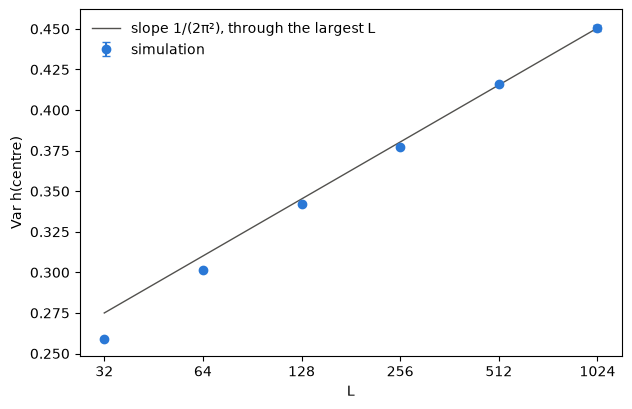

In [4]:
Ls = np.array(sorted(res))
if len(Ls) < 2:
    print("need at least two sizes with data; check again later")
else:
    var = np.array([res[L]["var"] for L in Ls])
    err = np.array([res[L]["var_se"] for L in Ls])
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.errorbar(np.log(Ls), var, yerr=err, fmt="o", color="#2a78d6", capsize=3, label="simulation")
    ax.plot(np.log(Ls), var[-1] + (np.log(Ls) - np.log(Ls[-1])) / (2 * np.pi ** 2), color="#52514e", lw=1,
            label="slope 1/(2π²), through the largest L")
    ax.set_xticks(np.log(Ls)); ax.set_xticklabels(Ls)
    ax.set_xlabel("L"); ax.set_ylabel("Var h(centre)"); ax.legend(frameon=False)
    plt.show()

In [5]:
Ls = np.array(sorted(res)); v = np.array([res[L]["var"] for L in Ls]); e = np.array([res[L]["var_se"] for L in Ls])
print("slope b in Var = a + b ln L (theory %.4f)" % (1 / (2 * np.pi**2)))
for Lmin in (32, 64, 128, 256):
    m = Ls >= Lmin
    if m.sum() < 3: continue
    x, w = np.log(Ls[m]), 1 / e[m]**2
    A = np.vstack([np.ones(m.sum()), x]).T
    cov = np.linalg.inv(A.T @ (A * w[:, None])); a, b = cov @ (A.T @ (w * v[m]))
    chi2 = np.sum(w * (v[m] - A @ [a, b])**2)
    print(f"  L >= {Lmin:4d}: b = {b:.4f} +- {np.sqrt(cov[1, 1]):.4f}   chi2 = {chi2:.2f} / {m.sum() - 2} dof")

slope b in Var = a + b ln L (theory 0.0507)
  L >=   32: b = 0.0560 +- 0.0003   chi2 = 48.21 / 4 dof
  L >=   64: b = 0.0543 +- 0.0004   chi2 = 13.73 / 3 dof
  L >=  128: b = 0.0528 +- 0.0006   chi2 = 4.67 / 2 dof
  L >=  256: b = 0.0541 +- 0.0011   chi2 = 2.68 / 1 dof


## 4. Picture of a saved sample (h and the three largest clusters)
Chain 0 of every size saved three samples.

['L1024_snapshot0.npz', 'L1024_snapshot1.npz', 'L1024_snapshot2.npz', 'L128_snapshot0.npz', 'L128_snapshot1.npz', 'L128_snapshot2.npz', 'L256_snapshot0.npz', 'L256_snapshot1.npz', 'L256_snapshot2.npz', 'L32_snapshot0.npz', 'L32_snapshot1.npz', 'L32_snapshot2.npz', 'L512_snapshot0.npz', 'L512_snapshot1.npz', 'L512_snapshot2.npz', 'L64_snapshot0.npz', 'L64_snapshot1.npz', 'L64_snapshot2.npz']


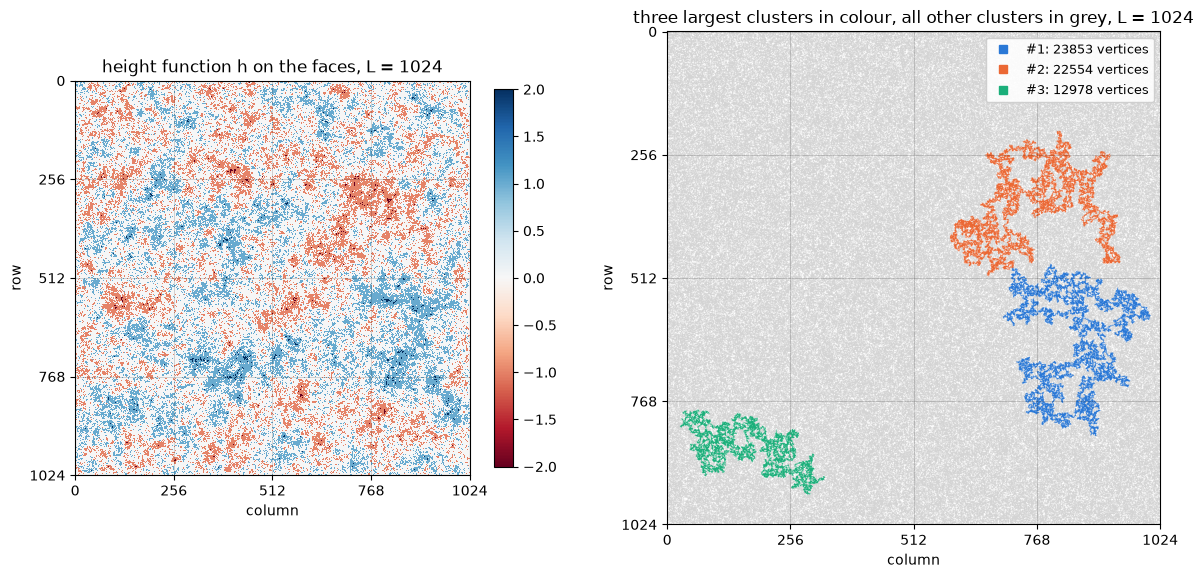

In [6]:
snaps = sorted(f for f in os.listdir(d.OUT_DIR) if f.endswith(".npz")) if os.path.isdir(d.OUT_DIR) else []
print(snaps)
L_show = 1024      # any size listed above
k_show = 0         # snapshot number: 0, 1 or 2
path = os.path.join(d.OUT_DIR, f"L{L_show}_snapshot{k_show}.npz")
if not os.path.exists(path):
    print("no snapshot for this size yet")
else:
    L, omega1, omega2, h, n_odd = d.load_snapshot(path)
    lab, sizes = d.cluster_labels(L, omega1, omega2)
    big = np.argsort(sizes)[::-1][:3]
    colours = [(42, 120, 214), (235, 104, 52), (27, 175, 122)]           # blue, orange, green
    img = np.full((L, L, 3), 255, dtype=np.uint8)
    img[sizes[lab] >= 2] = (212, 212, 212)           # every other cluster in grey: the whole domain stays visible
    for rank, c in enumerate(big):
        img[lab == c] = colours[rank]
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    vmax = max(1, np.abs(h).max())
    im = axes[0].imshow(h, cmap="RdBu", vmin=-vmax, vmax=vmax, interpolation="nearest",
                        extent=(0.5, L - 0.5, L - 0.5, 0.5))
    axes[0].set_title(f"height function h on the faces, L = {L}")
    fig.colorbar(im, ax=axes[0], shrink=0.7)
    axes[1].imshow(img, interpolation="nearest" if L <= 256 else "antialiased", extent=(-0.5, L - 0.5, L - 0.5, -0.5))
    axes[1].set_title(f"three largest clusters in colour, all other clusters in grey, L = {L}")
    axes[1].legend(handles=[plt.Line2D([], [], marker="s", ls="", color=np.array(colours[r]) / 255,
                                       label=f"#{r + 1}: {sizes[big[r]]} vertices") for r in range(3)],
                   loc="upper right", fontsize=9, framealpha=0.9)
    for a in axes:
        a.set_xticks(np.linspace(0, L, 5)); a.set_yticks(np.linspace(0, L, 5))
        a.grid(True, color="k", alpha=0.18, lw=0.6)
        a.set_xlabel("column"); a.set_ylabel("row")
    plt.show()